# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from mlxtend.frequent_patterns import fpgrowth, association_rules

df = pd.read_csv("bread_basket.csv")
print("Rows:", len(df), "| Unique transactions:", df["transaction"].nunique(), "| Unique items:", df["item"].nunique())
df.head()

Rows: 20507 | Unique transactions: 9465 | Unique items: 94


,transaction,item,date_time,time,period_day,weekday_weekend
0,1,Bread,30/10/2016,9:58,morning,weekend
1,2,Scandinavian,30/10/2016,10:05,morning,weekend
2,2,Scandinavian,30/10/2016,10:05,morning,weekend
3,3,Hot chocolate,30/10/2016,10:07,morning,weekend
4,3,Jam,30/10/2016,10:07,morning,weekend


## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [2]:
# a) Variables and their dtypes
print(df.dtypes)

transaction        int64
item                 str
date_time            str
time                 str
period_day           str
weekday_weekend      str
dtype: object


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [3]:
# b) Statistics overview
df.describe(include="all")

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

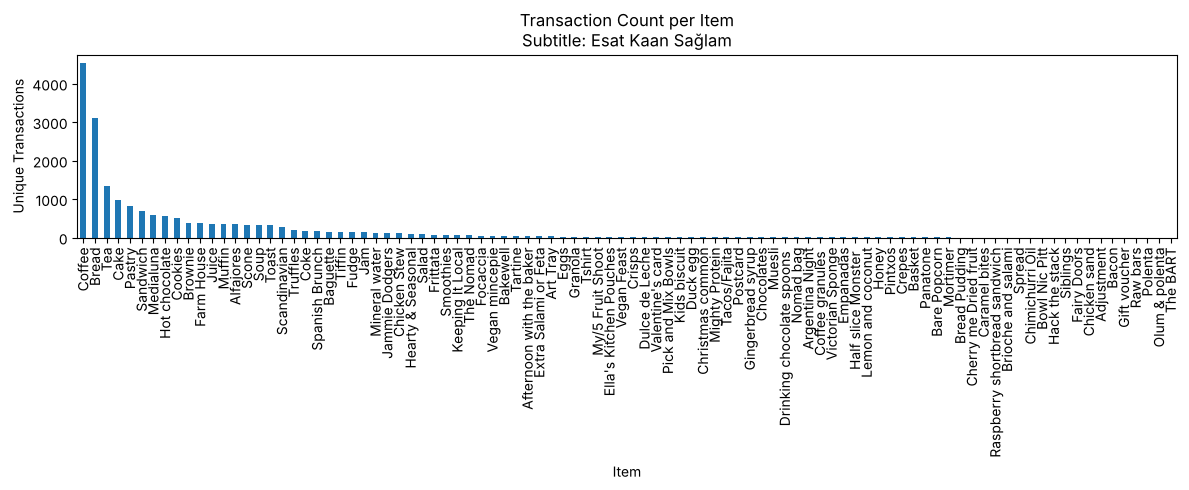

In [4]:
# c) Bar plot of transaction counts per item
subtitle = "Esat Kaan Sağlam"
# Count UNIQUE transactions per item (the same item can repeat inside one transaction)
item_counts = (df.groupby("item")["transaction"]
                 .nunique()
                 .sort_values(ascending=False))

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [5]:
# d) Counts (unique transactions) for selected items
selected = ["Coffee", "Tea", "Alfajores", "Juice", "Chicken Stew"]
print(item_counts.loc[selected].to_string())

item
Coffee          4528
Tea             1350
Alfajores        344
Juice            365
Chicken Stew     123


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [6]:
# One-hot transaction x item table (boolean); drop duplicate item rows within a transaction
basket = (df.drop_duplicates(["transaction", "item"])
            .assign(v=True)
            .pivot(index="transaction", columns="item", values="v")
            .fillna(False)
            .astype(bool))
print("One-hot shape:", basket.shape)

frequent_itemsets = fpgrowth(basket, min_support=0.02, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False).reset_index(drop=True)
print("Number of frequent itemsets:", len(frequent_itemsets))
frequent_itemsets

One-hot shape: (9465, 94)
Number of frequent itemsets: 33


,support,itemsets,length
0,0.478394,frozenset({Coffee}),1
1,0.327205,frozenset({Bread}),1
2,0.142631,frozenset({Tea}),1
3,0.103856,frozenset({Cake}),1
4,0.090016,"frozenset({Coffee, Bread})",2
5,0.086107,frozenset({Pastry}),1
6,0.071844,frozenset({Sandwich}),1
7,0.061807,frozenset({Medialuna}),1
8,0.058320,frozenset({Hot chocolate}),1
9,0.054728,"frozenset({Coffee, Cake})",2


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [7]:
# min_threshold = 0.10: low enough to keep rules linking Bread, Coffee, Cake, Tea
# (at 0.30 only 10 rules remain and the Bread/Cake/Tea edges disappear)
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    print(f"confidence >= {t}: {len(association_rules(frequent_itemsets, metric='confidence', min_threshold=t))} rules")

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.10)
report = rules[["antecedents", "consequents", "support", "confidence", "lift"]].copy()
report["antecedents"] = report["antecedents"].apply(lambda s: ", ".join(sorted(s)))
report["consequents"] = report["consequents"].apply(lambda s: ", ".join(sorted(s)))
report = report.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True).round(4)
print("\nSelected min_threshold = 0.10 ->", len(report), "rules")
report

confidence >= 0.1: 18 rules
confidence >= 0.2: 13 rules
confidence >= 0.3: 10 rules
confidence >= 0.4: 8 rules
confidence >= 0.5: 8 rules

Selected min_threshold = 0.10 -> 18 rules


,antecedents,consequents,support,confidence,lift
0,Tea,Cake,0.0238,0.1667,1.6048
1,Cake,Tea,0.0238,0.2289,1.6048
2,Toast,Coffee,0.0237,0.7044,1.4724
3,Medialuna,Coffee,0.0352,0.5692,1.1899
4,Pastry,Coffee,0.0475,0.5521,1.1542
5,Juice,Coffee,0.0206,0.5342,1.1167
6,Sandwich,Coffee,0.0382,0.5324,1.1128
7,Cake,Coffee,0.0547,0.5270,1.1015
8,Coffee,Cake,0.0547,0.1144,1.1015
9,Cookies,Coffee,0.0282,0.5184,1.0837


## 5) Rule Subgraph (Bread, Coffee, Cake, Tea) (5 pts)
Directed graph of the rules whose antecedent and consequent both belong to {Bread, Coffee, Cake, Tea}.

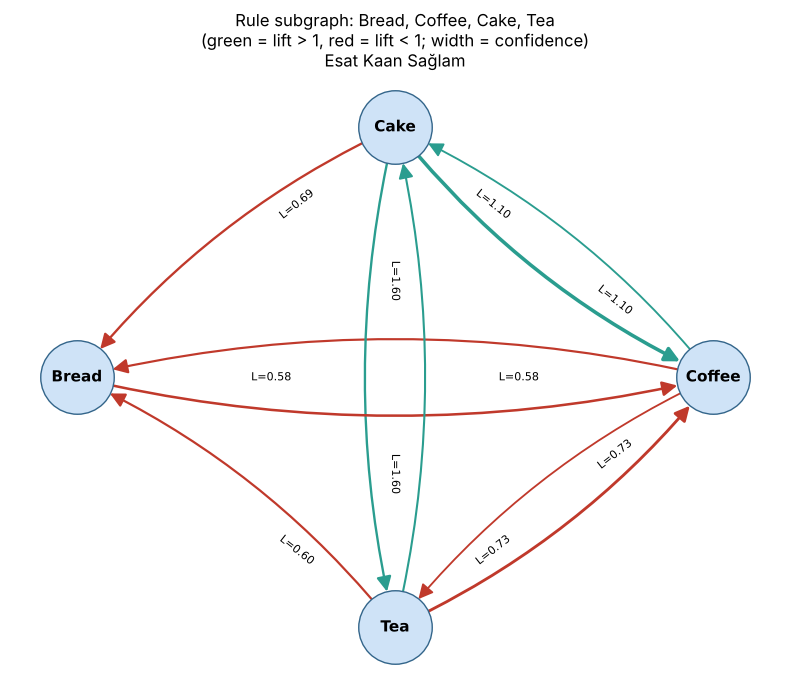

In [8]:
focus = {"Bread", "Coffee", "Cake", "Tea"}
sub = rules[rules["antecedents"].apply(lambda s: s <= focus) & rules["consequents"].apply(lambda s: s <= focus)]

G = nx.DiGraph()
G.add_nodes_from(focus)
for _, r in sub.iterrows():
    a, c = list(r["antecedents"])[0], list(r["consequents"])[0]
    G.add_edge(a, c, lift=r["lift"], conf=r["confidence"])

pos = nx.circular_layout(G)
plt.figure(figsize=(8, 7))
nx.draw_networkx_nodes(G, pos, node_size=2800, node_color="#cfe3f7", edgecolors="#33658a")
nx.draw_networkx_labels(G, pos, font_size=11, font_weight="bold")
edge_colors = ["#2a9d8f" if d["lift"] > 1 else "#c0392b" for _, _, d in G.edges(data=True)]
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, arrows=True, arrowsize=22,
                       width=[1 + 3*d["conf"] for _, _, d in G.edges(data=True)],
                       connectionstyle="arc3,rad=0.12", node_size=2800)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"L={d['lift']:.2f}" for u, v, d in G.edges(data=True)},
                             font_size=8, label_pos=0.3)
plt.title("Rule subgraph: Bread, Coffee, Cake, Tea\n(green = lift > 1, red = lift < 1; width = confidence)\nEsat Kaan Sağlam")
plt.axis("off"); plt.tight_layout(); plt.show()

## 6) Interpretation (5 pts)

In [9]:
# Metrics for {Coffee, Cake} => {Bread}, computed directly from the basket table
# (this 3-item set has support < 0.02, so FP-Growth at min_support=0.02 does not return it)
n = len(basket)
cc = basket["Coffee"] & basket["Cake"]
ccb = cc & basket["Bread"]
support = ccb.sum() / n
confidence = ccb.sum() / cc.sum()
lift = confidence / basket["Bread"].mean()
print(f"Transactions with Coffee+Cake: {cc.sum()} | with Coffee+Cake+Bread: {ccb.sum()} | total: {n}")
print(f"support = {support:.4f}, confidence = {confidence:.4f}, P(Bread) = {basket['Bread'].mean():.4f}, lift = {lift:.4f}")

Transactions with Coffee+Cake: 518 | with Coffee+Cake+Bread: 95 | total: 9465
support = 0.0100, confidence = 0.1834, P(Bread) = 0.3272, lift = 0.5605


**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support = 0.0100 (about 1.0%)**: 95 of the 9,465 transactions contain Coffee, Cake, and Bread together. It is a rare combination, which is why this 3-item set is below the 0.02 support cutoff and does not appear among the frequent itemsets.
- **Confidence = 0.1834 (about 18.3%)**: 518 baskets contain Coffee and Cake, and only 95 of them (18.3%) also include Bread.
- **Lift = 0.56 (< 1)**: Bread is in 32.7% of all baskets, but only 18.3% of Coffee+Cake baskets. So customers who buy Coffee and Cake are *less* likely than average to add Bread. This is a negative association (substitution / different shopping missions), not a positive one, so the "lift > 1" case does not apply here.
- **Practical meaning**: do not bundle or cross-promote Bread with Coffee + Cake. The Coffee + Cake basket looks like a café/snack purchase, while Bread is bought on its own or with other items. Bread promotions are better aimed elsewhere, e.g. Pastry (Pastry ⇒ Bread has lift ≈ 1.03).

>